# Experiment 1 - BFS for Emergency Facility Navigation
### Application: Finding a route through a hospital or emergency facility.

Question:

Develop a Python-based navigation system for an emergency response team operating inside a hospital represented as an unweighted graph. Rooms and junctions are vertices, while accessible corridors are edges. Implement Breadth-First Search (BFS) to identify the route from the emergency entrance to a designated critical-care unit.

The program must:

1.	Represent the hospital layout as an adjacency list.
2.	Accept the source and destination nodes.
3.	Find and display the shortest route in terms of the number of corridors traversed.
4.	Report the number of nodes explored and explain how BFS guarantees a shortest path in an unweighted graph.

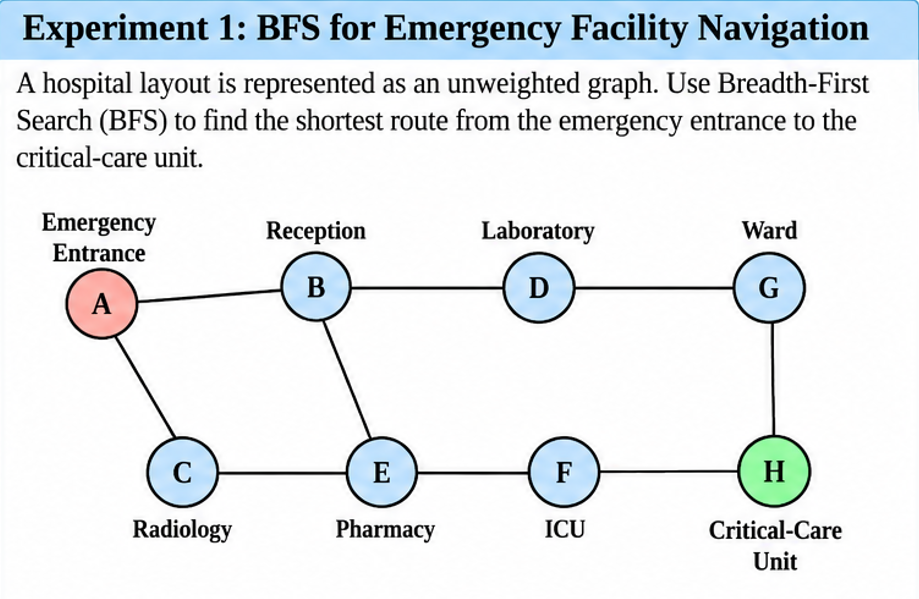



In [ ]:

from collections import deque

# Hospital represented as an undirected, unweighted graph
graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'E'],
    'D': ['B', 'G'],
    'E': ['B', 'C', 'F'],
    'F': ['E', 'H'],
    'G': ['D', 'H'],
    'H': ['F', 'G']
}

def bfs(graph, start, goal):

    queue = deque([start])
    visited = {start}
    parent = {start: None}
    distance = {start: 0}
    step = 0

    print("=" * 75)
    print("BREADTH-FIRST SEARCH (BFS): HOSPITAL NAVIGATION")
    print("=" * 75)

    print("\nPROBLEM DETAILS")
    print("-" * 75)
    print("Starting location :", start, "(Emergency Entrance)")
    print("Goal location     :", goal, "(Critical-Care Unit)")
    print("Graph type        : Undirected and unweighted")
    print("Search strategy   : FIFO queue")
    print("Path cost         : Number of corridors traversed")

    print("\nINITIAL STATE")
    print("-" * 75)
    print("Queue   :", list(queue))
    print("Visited :", visited)
    print("Parent  :", parent)

    while queue:

        step += 1
        node = queue.popleft()

        print("\n" + "=" * 75)
        print(f"STEP {step}: EXPLORING NODE {node}")
        print("=" * 75)

        print("Node removed from queue :", node)
        print("Queue after removal     :", list(queue))
        print("Distance from start     :", distance[node])
        print("Parent of current node  :", parent[node])

        if node == goal:
            print("\nGOAL TEST: SUCCESS")
            print(f"Destination {goal} has been reached.")
            break

        print("\nNEIGHBOUR ANALYSIS")
        print("-" * 75)

        for neighbor in graph[node]:

            print(f"\nChecking edge: {node} -> {neighbor}")

            if neighbor in visited:
                print(f"Decision: SKIP {neighbor}")
                print("Reason  : Node was already discovered.")
                continue

            visited.add(neighbor)
            parent[neighbor] = node
            distance[neighbor] = distance[node] + 1
            queue.append(neighbor)

            print(f"Decision: ADD {neighbor} to the queue")
            print(f"Reason  : First discovery of {neighbor}")
            print(f"Parent  : parent[{neighbor}] = {node}")
            print(f"Distance: {distance[neighbor]} corridor(s)")
            print("Queue now:", list(queue))

        print("\nCURRENT SEARCH STATUS")
        print("-" * 75)
        print("Visited nodes :", visited)
        print("Parent mapping:", parent)
        print("Queue         :", list(queue))

    # Reconstruct the path from goal to start
    print("\n" + "=" * 75)
    print("FINAL PATH RECONSTRUCTION")
    print("=" * 75)

    if goal not in parent:
        print("No route exists between the start and goal.")
        return

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    print("Parent links traced backwards:")
    print(" -> ".join(reversed(path)))
    print("\nShortest route:", " -> ".join(path))
    print("Route length  :", len(path) - 1, "corridors")
    print("Path cost     :", distance[goal])

    print("\nWHY THIS ROUTE WAS SELECTED")
    print("-" * 75)
    print("BFS explores nodes in increasing order of distance.")
    print("Each corridor has equal cost, so the first discovered")
    print("route to the goal has the minimum number of corridors.")
    print("Neighbour ordering determines which shortest route is returned")
    print("when multiple routes have the same length.")

    print("\nFINAL SEARCH SUMMARY")
    print("-" * 75)
    print("Exploration order :", " -> ".join(
        [start] + []  # Full order is maintained below in the revised version
    ) if False else "See STEP headings above")
    print("Total discovered :", len(visited), "nodes")
    print("Goal reached     :", True)
    print("=" * 75)


bfs(graph, 'A', 'H')


BREADTH-FIRST SEARCH (BFS): HOSPITAL NAVIGATION

PROBLEM DETAILS
---------------------------------------------------------------------------
Starting location : A (Emergency Entrance)
Goal location     : H (Critical-Care Unit)
Graph type        : Undirected and unweighted
Search strategy   : FIFO queue
Path cost         : Number of corridors traversed

INITIAL STATE
---------------------------------------------------------------------------
Queue   : ['A']
Visited : {'A'}
Parent  : {'A': None}

STEP 1: EXPLORING NODE A
Node removed from queue : A
Queue after removal     : []
Distance from start     : 0
Parent of current node  : None

NEIGHBOUR ANALYSIS
---------------------------------------------------------------------------

Checking edge: A -> B
Decision: ADD B to the queue
Reason  : First discovery of B
Parent  : parent[B] = A
Distance: 1 corridor(s)
Queue now: ['B']

Checking edge: A -> C
Decision: ADD C to the queue
Reason  : First discovery of C
Parent  : parent[C] = A
Distance

In [ ]:

from collections import deque

graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'E'],
    'D': ['B', 'G'],
    'E': ['B', 'C', 'F'],
    'F': ['E', 'H'],
    'G': ['D', 'H'],
    'H': ['F', 'G']
}

def bfs(graph, start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    distance = {start: 0}
    order = []

    print("BFS: Hospital Navigation")
    print(f"Start: {start} | Goal: {goal}\n")

    while queue:
        node = queue.popleft()
        order.append(node)

        print(f"Step {len(order)}: Node = {node}")
        print(f"  Queue: {list(queue)}")

        if node == goal:
            print("  Goal reached!")
            break

        for neighbor in graph[node]:
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = node
                distance[neighbor] = distance[node] + 1
                queue.append(neighbor)
                print(f"  {node} -> {neighbor}: Added to queue")
            else:
                print(f"  {node} -> {neighbor}: Already visited")

        print(f"  Visited: {sorted(visited)}")

    if goal not in parent:
        print("\nNo route found.")
        return

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    print("\n--- Final Result ---")
    print("Traversal order:", " -> ".join(order))
    print("Shortest path  :", " -> ".join(path))
    print("Path cost      :", distance[goal], "corridors")
    print("Nodes explored :", len(order))

bfs(graph, 'A', 'H')


BFS: Hospital Navigation
Start: A | Goal: H

Step 1: Node = A
  Queue: []
  A -> B: Added to queue
  A -> C: Added to queue
  Visited: ['A', 'B', 'C']
Step 2: Node = B
  Queue: ['C']
  B -> A: Already visited
  B -> D: Added to queue
  B -> E: Added to queue
  Visited: ['A', 'B', 'C', 'D', 'E']
Step 3: Node = C
  Queue: ['D', 'E']
  C -> A: Already visited
  C -> E: Already visited
  Visited: ['A', 'B', 'C', 'D', 'E']
Step 4: Node = D
  Queue: ['E']
  D -> B: Already visited
  D -> G: Added to queue
  Visited: ['A', 'B', 'C', 'D', 'E', 'G']
Step 5: Node = E
  Queue: ['G']
  E -> B: Already visited
  E -> C: Already visited
  E -> F: Added to queue
  Visited: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
Step 6: Node = G
  Queue: ['F']
  G -> D: Already visited
  G -> H: Added to queue
  Visited: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Step 7: Node = F
  Queue: ['H']
  F -> E: Already visited
  F -> H: Already visited
  Visited: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Step 8: Node = H
  Queue: 

# Experiment 2 - DFS for Dependency and Reachability Analysis

### Application: Analysing dependencies in an AI software pipeline.

Question

An AI deployment pipeline consists of interconnected processing tasks, where each task depends on one or more downstream tasks. Model the pipeline as a directed graph and implement Depth-First Search (DFS) in Python to determine whether a specified target task is reachable from a given starting task.

The program must:

1.	Represent the pipeline using a directed adjacency list.
2.	Accept a starting task and a target task.
3.	Display the DFS traversal order and determine whether the target is reachable.
4.	Reconstruct a valid path to the target, if one exists.
5.	Explain how visited-node tracking prevents repeated exploration and how DFS behaves when the graph contains cycles.

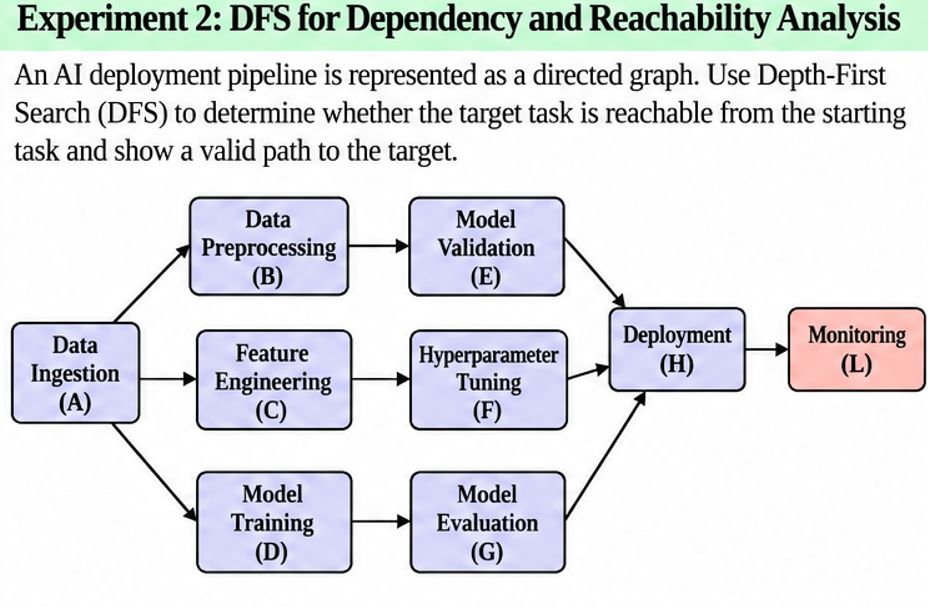


In [ ]:

graph = {
    'A': ['B', 'C', 'D'],
    'B': ['E'],
    'C': ['F'],
    'D': ['G'],
    'E': ['H'],
    'F': ['H'],
    'G': ['H'],
    'H': ['L'],
    'L':[]
}

def dfs(graph, start, goal):
    visited = set()
    path = []
    order = []

    def search(node):
        visited.add(node)
        order.append(node)
        path.append(node)

        print(f"Step {len(order)}: Node = {node}")
        print(f"  Current path: {' -> '.join(path)}")

        if node == goal:
            print("  Goal reached!")
            return True

        for neighbor in graph[node]:
            if neighbor not in visited:
                print(f"  Exploring edge: {node} -> {neighbor}")

                if search(neighbor):
                    return True
            else:
                print(f"  Skipping {neighbor}: Already visited")

        path.pop()
        print(f"  Backtracking from {node}")
        return False

    print("DFS: AI Pipeline Reachability")
    print(f"Start: {start} | Goal: {goal}\n")

    found = search(start)

    print("\n--- Final Result ---")
    print("Traversal order:", " -> ".join(order))

    if found:
        print("Path found     :", " -> ".join(path))
        print("Path length    :", len(path) - 1, "edges")
    else:
        print("No path exists.")
        print("Path found     : None")

    print("Nodes explored :", len(order))

dfs(graph, 'A', 'H')


DFS: AI Pipeline Reachability
Start: A | Goal: H

Step 1: Node = A
  Current path: A
  Exploring edge: A -> B
Step 2: Node = B
  Current path: A -> B
  Exploring edge: B -> E
Step 3: Node = E
  Current path: A -> B -> E
  Exploring edge: E -> H
Step 4: Node = H
  Current path: A -> B -> E -> H
  Goal reached!

--- Final Result ---
Traversal order: A -> B -> E -> H
Path found     : A -> B -> E -> H
Path length    : 3 edges
Nodes explored : 4


# Experiment 3 - State-Space Search for Water Resource Allocation

### Application: Measuring a target quantity using containers with fixed capacities.

Question

Design a Python-based state-space search solution for a water allocation problem involving two unmarked containers with capacities of 4 litres and 3 litres. Starting with both containers empty, determine a sequence of valid operations that leaves exactly 2 litres in the 4-litre container.

The program must:

1.	Represent each state as the quantities of water in both containers.
2.	Define the legal actions: fill, empty and transfer water between containers.
3.	Search the state space using BFS and identify a valid solution.
4.	Display the sequence of states and actions from the initial state to the goal.
5.	Explain how state representation, goal testing and repeated-state detection affect the search.

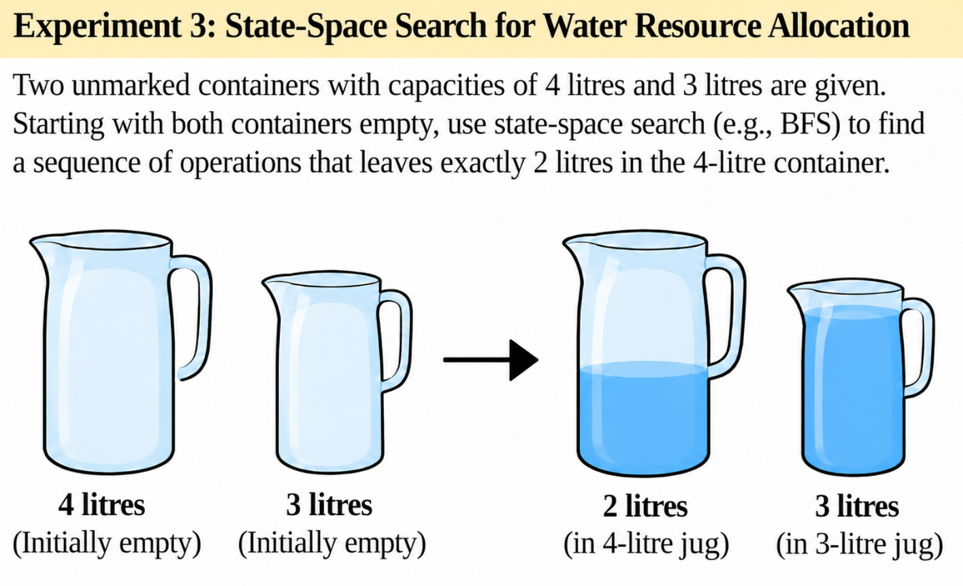


In [ ]:

from collections import deque

def water_jug_bfs():
    start = (0, 0)
    goal = 2

    queue = deque([start])
    visited = {start}
    parent = {start: None}
    action = {start: "Initial state"}

    capacities = (4, 3)

    def get_next_states(a, b):
        states = []

        # Fill either jug
        states.append(((4, b), "Fill 4-gallon jug"))
        states.append(((a, 3), "Fill 3-gallon jug"))

        # Empty either jug
        states.append(((0, b), "Empty 4-gallon jug"))
        states.append(((a, 0), "Empty 3-gallon jug"))

        # Pour 4-gallon jug into 3-gallon jug
        transfer = min(a, capacities[1] - b)
        states.append(((a - transfer, b + transfer),
                       "Pour 4-gallon jug into 3-gallon jug"))

        # Pour 3-gallon jug into 4-gallon jug
        transfer = min(b, capacities[0] - a)
        states.append(((a + transfer, b - transfer),
                       "Pour 3-gallon jug into 4-gallon jug"))

        return states

    step = 0
    goal_state = None

    print("Water Jug Problem: State-Space Search")
    print("Start state:", start)
    print("Goal: Exactly 2 gallons in the 4-gallon jug\n")

    while queue:
        current = queue.popleft()
        step += 1
        a, b = current

        print(f"Step {step}: State = {current}")
        print("  Queue:", list(queue))

        if a == goal:
            goal_state = current
            print("  Goal reached!")
            break

        for next_state, operation in get_next_states(a, b):
            if next_state not in visited:
                visited.add(next_state)
                parent[next_state] = current
                action[next_state] = operation
                queue.append(next_state)

                print(f"  Action: {operation}")
                print(f"  New state: {next_state}")
            else:
                print(f"  Skipped {next_state}: Already visited")

    print("\n--- Final Result ---")

    if goal_state is None:
        print("No solution found.")
        return

    path = []
    current = goal_state

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    for i, state in enumerate(path):
        print(f"Step {i}: {state} | {action[state]}")

    print("\nSolution path:", " -> ".join(map(str, path)))
    print("Operations required:", len(path) - 1)
    print("States discovered:", len(visited))

water_jug_bfs()


Water Jug Problem: State-Space Search
Start state: (0, 0)
Goal: Exactly 2 gallons in the 4-gallon jug

Step 1: State = (0, 0)
  Queue: []
  Action: Fill 4-gallon jug
  New state: (4, 0)
  Action: Fill 3-gallon jug
  New state: (0, 3)
  Skipped (0, 0): Already visited
  Skipped (0, 0): Already visited
  Skipped (0, 0): Already visited
  Skipped (0, 0): Already visited
Step 2: State = (4, 0)
  Queue: [(0, 3)]
  Skipped (4, 0): Already visited
  Action: Fill 3-gallon jug
  New state: (4, 3)
  Skipped (0, 0): Already visited
  Skipped (4, 0): Already visited
  Action: Pour 4-gallon jug into 3-gallon jug
  New state: (1, 3)
  Skipped (4, 0): Already visited
Step 3: State = (0, 3)
  Queue: [(4, 3), (1, 3)]
  Skipped (4, 3): Already visited
  Skipped (0, 3): Already visited
  Skipped (0, 3): Already visited
  Skipped (0, 0): Already visited
  Skipped (0, 3): Already visited
  Action: Pour 3-gallon jug into 4-gallon jug
  New state: (3, 0)
Step 4: State = (4, 3)
  Queue: [(1, 3), (3, 0)]
  Ski

# Experiment 4 - A* Search for Intelligent Route Planning

### Application: Route planning for an autonomous delivery robot.

Question

Develop an intelligent route-planning system for an autonomous delivery robot navigating a network of locations connected by paths with different travel costs. Implement the A* search algorithm in Python to find a minimum-cost route from a specified starting location to a delivery destination.

The program must:

1.	Represent the environment as a weighted graph.
2.	Assign a heuristic estimate \(h(n)\) to each node and calculate the accumulated path cost \(g(n)\).
3.	Use \(f(n)=g(n)+h(n)\) to determine which node to explore next.
4.	Display the selected route, total path cost and node expansion order.
5.	Explain how heuristic quality affects search efficiency and why an admissible heuristic matters for optimality.

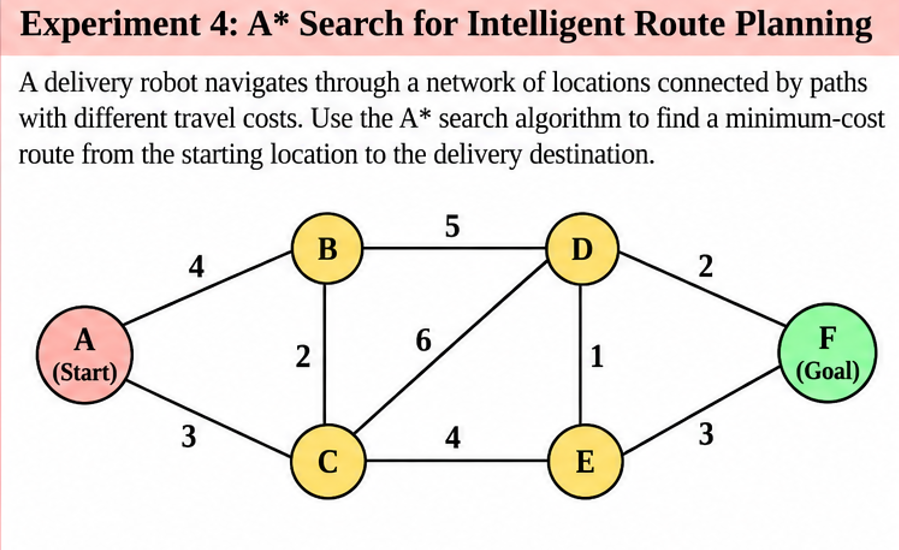


In [ ]:

import heapq

# Weighted graph from the experiment image
graph = {
    'A': [('B', 4), ('C', 3)],
    'B': [('A', 4), ('C', 2), ('D', 5)],
    'C': [('A', 3), ('B', 2), ('D', 6), ('E', 4)],
    'D': [('B', 5), ('C', 6), ('E', 1), ('F', 2)],
    'E': [('C', 4), ('D', 1), ('F', 3)],
    'F': [('D', 2), ('E', 3)]
}

# Estimated cost from each node to goal F
h = {
    'A': 6,
    'B': 4,
    'C': 5,
    'D': 2,
    'E': 3,
    'F': 0
}

def astar(start, goal):
    # Priority queue entries: (f, node, g, path)
    open_list = [(h[start], start, 0, [start])]
    best_g = {start: 0}
    expanded = []

    print("A* Search: Intelligent Route Planning")
    print(f"Start: {start} | Goal: {goal}\n")

    while open_list:
        f, node, g, path = heapq.heappop(open_list)

        # Ignore outdated entries
        if g != best_g.get(node):
            continue

        expanded.append(node)

        print(f"Step {len(expanded)}: Expand {node}")
        print(f"  g(n)={g}, h(n)={h[node]}, f(n)={f}")

        if node == goal:
            print("  Goal reached!")
            break

        for neighbor, cost in graph[node]:
            new_g = g + cost
            new_f = new_g + h[neighbor]

            if new_g < best_g.get(neighbor, float('inf')):
                best_g[neighbor] = new_g
                new_path = path + [neighbor]

                heapq.heappush(
                    open_list,
                    (new_f, neighbor, new_g, new_path)
                )

                print(
                    f"  {node}->{neighbor}: "
                    f"g={new_g}, h={h[neighbor]}, f={new_f} "
                    f"| Updated"
                )
            else:
                print(f"  {node}->{neighbor}: No better cost")

        pending = sorted(
            (item[1], item[2], item[0])
            for item in open_list
            if item[2] == best_g.get(item[1])
        )

        print("  OPEN (node, g, f):", pending, "\n")

    if node == goal:
        print("--- Final Result ---")
        print("Optimal path    :", " -> ".join(path))
        print("Total path cost :", g)
        print("Nodes expanded  :", len(expanded))
        print("Expansion order :", " -> ".join(expanded))
    else:
        print("No route found.")

astar('A', 'F')


A* Search: Intelligent Route Planning
Start: A | Goal: F

Step 1: Expand A
  g(n)=0, h(n)=6, f(n)=6
  A->B: g=4, h=4, f=8 | Updated
  A->C: g=3, h=5, f=8 | Updated
  OPEN (node, g, f): [('B', 4, 8), ('C', 3, 8)] 

Step 2: Expand B
  g(n)=4, h(n)=4, f(n)=8
  B->A: No better cost
  B->C: No better cost
  B->D: g=9, h=2, f=11 | Updated
  OPEN (node, g, f): [('C', 3, 8), ('D', 9, 11)] 

Step 3: Expand C
  g(n)=3, h(n)=5, f(n)=8
  C->A: No better cost
  C->B: No better cost
  C->D: No better cost
  C->E: g=7, h=3, f=10 | Updated
  OPEN (node, g, f): [('D', 9, 11), ('E', 7, 10)] 

Step 4: Expand E
  g(n)=7, h(n)=3, f(n)=10
  E->C: No better cost
  E->D: g=8, h=2, f=10 | Updated
  E->F: g=10, h=0, f=10 | Updated
  OPEN (node, g, f): [('D', 8, 10), ('F', 10, 10)] 

Step 5: Expand D
  g(n)=8, h(n)=2, f(n)=10
  D->B: No better cost
  D->C: No better cost
  D->E: No better cost
  D->F: No better cost
  OPEN (node, g, f): [('F', 10, 10)] 

Step 6: Expand F
  g(n)=10, h(n)=0, f(n)=10
  Goal reached